#Clase 3

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
dataset_path = "/Users/carof/Downloads/DENICOLAY/"
dataset_file = 'competencia_01.csv'
#dict_file = 'diccionario.csv'
#dataset_filename = "competencia_01_crudo.csv"


ganancia_acierto = 1_072_500
costo_estimulo = 27_500

In [3]:
data = pd.read_csv(dataset_path+dataset_file)

In [4]:
mes_train = 202103

X = data[data['foto_mes'] == mes_train]
y = X['clase_ternaria']
X = X.drop(columns=['clase_ternaria'])

Defino funcion de ganancia

In [5]:
def ganancia(model, X, y, prop=1, threshold=0.025):

  class_index = np.where(model.classes_ == "BAJA+2")[0][0]
  y_hat = model.predict_proba(X)

  @np.vectorize
  def ganancia_row(predicted, actual, threshold=0.025):
    return  (predicted >= threshold) * (ganancia_acierto if actual == "BAJA+2" else -costo_estimulo)

  return ganancia_row(y_hat[:,class_index], y).sum() / prop

Comparo con una suerte de cross validation de montecarlo

In [14]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.tree import DecisionTreeClassifier

tree_params = {
    'criterion': 'gini',
    'max_depth': 5,
    'min_samples_split': 80
}

#lista de ganancias
gan_test = []
gan_train = [] # esta no se mira NUNCA, esta para sumar dibujitos

sss = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=42)

for train_index, test_index in sss.split(X, y):

  model = DecisionTreeClassifier(**tree_params)
  model.fit(X.iloc[train_index], y.iloc[train_index])

  gan_test.append(ganancia(model, X.iloc[test_index], y.iloc[test_index], prop=0.3))
  gan_train.append(ganancia(model, X.iloc[train_index], y.iloc[train_index], prop=0.7))

c:\Users\carof\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
c:\Users\carof\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)


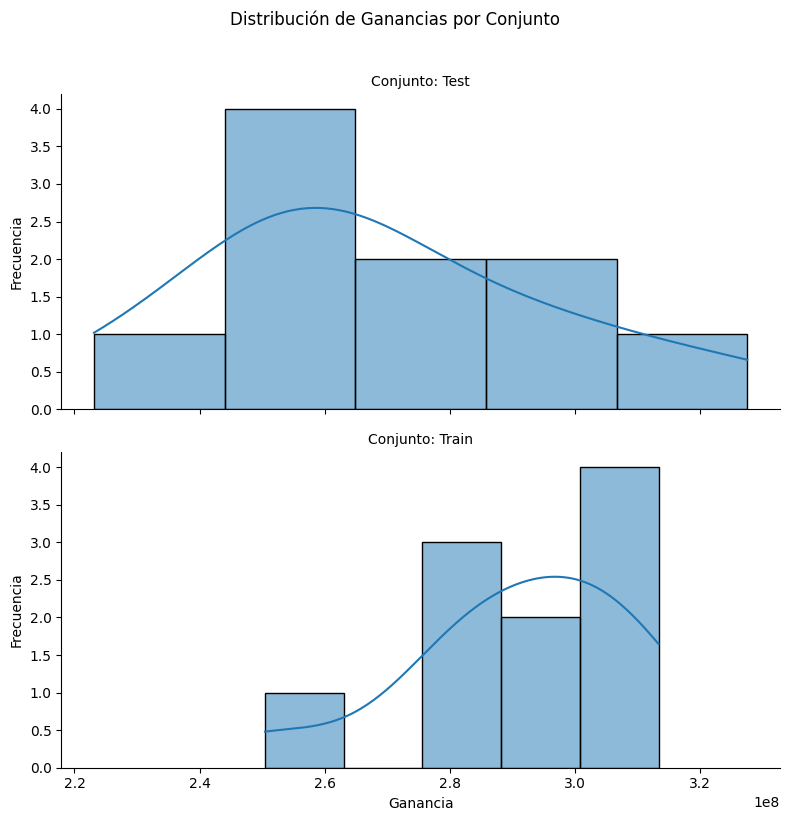

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# DataFrame for plotting
df_gains = pd.DataFrame({
    'Ganancia': gan_test + gan_train,
    'Conjunto': ['Test'] * len(gan_test) + ['Train'] * len(gan_train)
})

# Plot histograms using FacetGrid to stack them vertically
g = sns.FacetGrid(df_gains, row='Conjunto', aspect=2, height=4)
g.map(sns.histplot, 'Ganancia', kde=True, palette='viridis')
g.set_axis_labels('Ganancia', 'Frecuencia')
g.set_titles(row_template='Conjunto: {row_name}')
plt.suptitle('Distribución de Ganancias por Conjunto', y=1.02) # Add a main title
plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

In [ ]:
# 1. Definir los modelos o combinaciones de hiperparámetros a comparar
modelos_params = {
    'Tree_d3_s100': {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 100},
    'Tree_d5_s80':  {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 80},
    'Tree_d8_s40':  {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 40},
    'Tree_d12_s20': {'criterion': 'gini', 'max_depth': 12, 'min_samples_split': 20}
}

# 2. Configurar el validador
sss = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=42)

# 3. Almacenar resultados en formato tabular
resultados = []

for nombre_modelo, params in modelos_params.items():
    for fold, (train_index, test_index) in enumerate(sss.split(X, y)):
        
        model = DecisionTreeClassifier(**params)
        model.fit(X.iloc[train_index], y.iloc[train_index])
        
        # Calcular ganancias
        gan_test = ganancia(model, X.iloc[test_index], y.iloc[test_index], prop=0.3)
        gan_train = ganancia(model, X.iloc[train_index], y.iloc[train_index], prop=0.7)
        
        resultados.append({
            'modelo': nombre_modelo,
            'fold': fold,
            'ganancia_test': gan_test,
            'ganancia_train': gan_train
        })

df_res = pd.DataFrame(resultados)

In [17]:
metricas = df_res.groupby('modelo')['ganancia_test'].agg(['mean', 'std', 'median', 'min', 'max'])
print(metricas.sort_values(by='mean', ascending=False))

                      mean           std        median           min  \
modelo                                                                 
Tree_d8_s40   2.763475e+08  2.686280e+07  2.764208e+08  2.426417e+08   
Tree_d5_s80   2.687300e+08  2.989374e+07  2.631750e+08  2.231167e+08   
Tree_d12_s20  2.510842e+08  3.008934e+07  2.475458e+08  1.987333e+08   
Tree_d3_s100  2.381042e+08  2.392398e+07  2.419542e+08  1.915833e+08   

                       max  
modelo                      
Tree_d8_s40   3.241333e+08  
Tree_d5_s80   3.276167e+08  
Tree_d12_s20  3.013083e+08  
Tree_d3_s100  2.664750e+08  


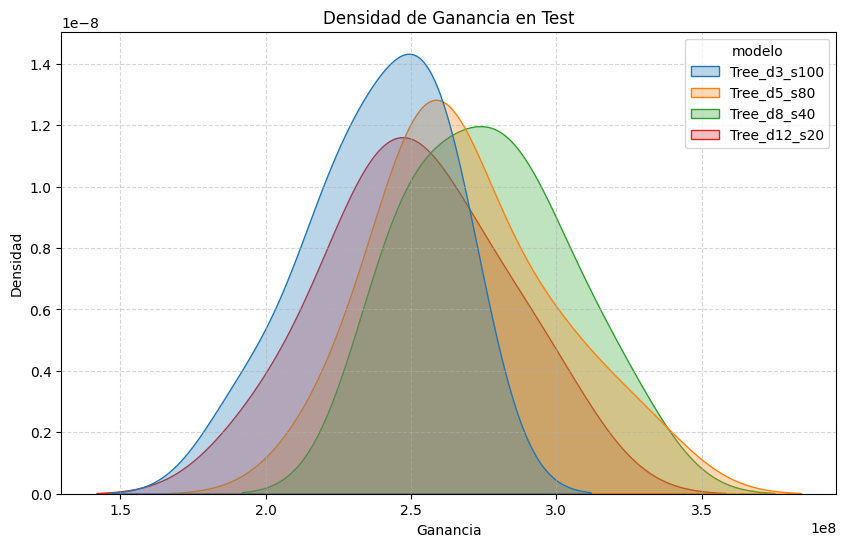

In [20]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df_res, x='ganancia_test', hue='modelo', fill=True, common_norm=False, alpha=0.3)
plt.title('Densidad de Ganancia en Test')
plt.xlabel('Ganancia')
plt.ylabel('Densidad')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

C:\Users\carof\AppData\Local\Temp\ipykernel_31208\261789500.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_res, x='modelo', y='ganancia_test', palette='Set2')


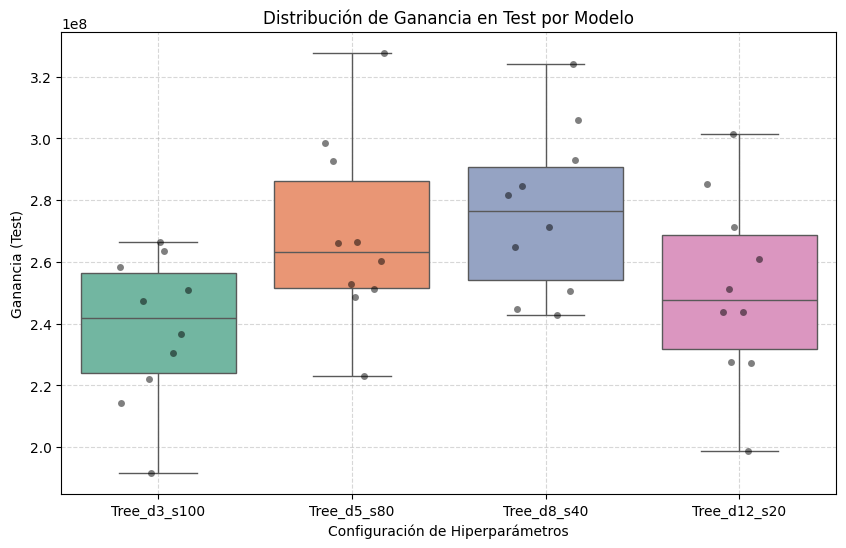

In [19]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_res, x='modelo', y='ganancia_test', palette='Set2')
sns.stripplot(data=df_res, x='modelo', y='ganancia_test', color='black', alpha=0.5, jitter=0.2)
plt.title('Distribución de Ganancia en Test por Modelo')
plt.xlabel('Configuración de Hiperparámetros')
plt.ylabel('Ganancia (Test)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Comparo mes a mes 

Corro otra vez mi codigo

In [8]:
mes_train = 202103
mes_test_1 = 202104
mes_test_2 = 202105

X_train = data[data['foto_mes'] == mes_train]
y_train = X_train['clase_ternaria']
X_train = X_train.drop(columns=['clase_ternaria'])


X_test_1 = data[data['foto_mes'] == mes_test_1]
y_test_1 = X_test_1['clase_ternaria']
X_test_1 = X_test_1.drop(columns=['clase_ternaria'])

X_test_2 = data[data['foto_mes'] == mes_test_2]
y_test_2 = X_test_2['clase_ternaria']
X_test_2 = X_test_2.drop(columns=['clase_ternaria'])

In [23]:
import pandas as pd
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.tree import DecisionTreeClassifier

# 1. Definir los modelos o combinaciones de hiperparámetros a comparar
modelos_params = {
    'Tree_d3_s100': {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 100},
    'Tree_d5_s80':  {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 80},
    'Tree_d8_s40':  {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 40},
    'Tree_d12_s20': {'criterion': 'gini', 'max_depth': 12, 'min_samples_split': 20}
}

# 2. Configurar el validador sobre los datos de entrenamiento (202103)
sss = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=42)

# 3. Almacenar resultados y objetos de modelos entrenados
resultados = []
modelos_guardados = []

for nombre_modelo, params in modelos_params.items():
    for fold, (train_index, test_index) in enumerate(sss.split(X_train, y_train)):
        
        # Instanciar y ajustar modelo
        model = DecisionTreeClassifier(**params, random_state=42)
        model.fit(X_train.iloc[train_index], y_train.iloc[train_index])
        
        # Calcular ganancias internas del mes de train
        gan_test = ganancia(model, X_train.iloc[test_index], y_train.iloc[test_index], prop=0.3)
        gan_train = ganancia(model, X_train.iloc[train_index], y_train.iloc[train_index], prop=0.7)
        
        # Guardar métricas
        resultados.append({
            'modelo': nombre_modelo,
            'fold': fold,
            'ganancia_test': gan_test,
            'ganancia_train': gan_train
        })
        
        # Guardar el objeto del modelo entrenado junto con sus metadatos
        modelos_guardados.append({
            'nombre_modelo': nombre_modelo,
            'fold': fold,
            'modelo_fit': model
        })

df_res_crossval = pd.DataFrame(resultados)

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

resultados_test = []

for item in modelos_guardados:
    nombre = item['nombre_modelo']
    fold = item['fold']
    modelo = item['modelo_fit']
    
    # Evaluar en mes test 1 (202104)
    gan_t1 = ganancia(modelo, X_test_1, y_test_1, prop=1.0)
    
    # Evaluar en mes test 2 (202105)
    gan_t2 = ganancia(modelo, X_test_2, y_test_2, prop=1.0)
    
    resultados_test.append({
        'modelo': nombre,
        'fold': fold,
        'ganancia_test_1 (202104)': gan_t1,
        'ganancia_test_2 (202105)': gan_t2
    })

df_test = pd.DataFrame(resultados_test)

# Resumen estadístico por modelo en cada mes
resumen = df_test.groupby('modelo').agg({
    'ganancia_test_1 (202104)': ['mean', 'std'],
    'ganancia_test_2 (202105)': ['mean', 'std']
})
print("Resumen de Ganancias en Meses Out-of-Time:")
print(resumen)

Resumen de Ganancias en Meses Out-of-Time:
             ganancia_test_1 (202104)               ganancia_test_2 (202105)  \
                                 mean           std                     mean   
modelo                                                                         
Tree_d12_s20              376417250.0  2.894132e+07              161364500.0   
Tree_d3_s100              353355750.0  1.593341e+07              160267250.0   
Tree_d5_s80               403469000.0  2.715701e+07              179294500.0   
Tree_d8_s40               410236750.0  2.811982e+07              181637500.0   

                            
                       std  
modelo                      
Tree_d12_s20  1.951487e+07  
Tree_d3_s100  7.793429e+06  
Tree_d5_s80   8.507396e+06  
Tree_d8_s40   1.805403e+07  


C:\Users\carof\AppData\Local\Temp\ipykernel_31208\794761471.py:11: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df_plot, x='modelo', y='ganancia', hue='periodo_test', dodge=True, color='black', alpha=0.6)


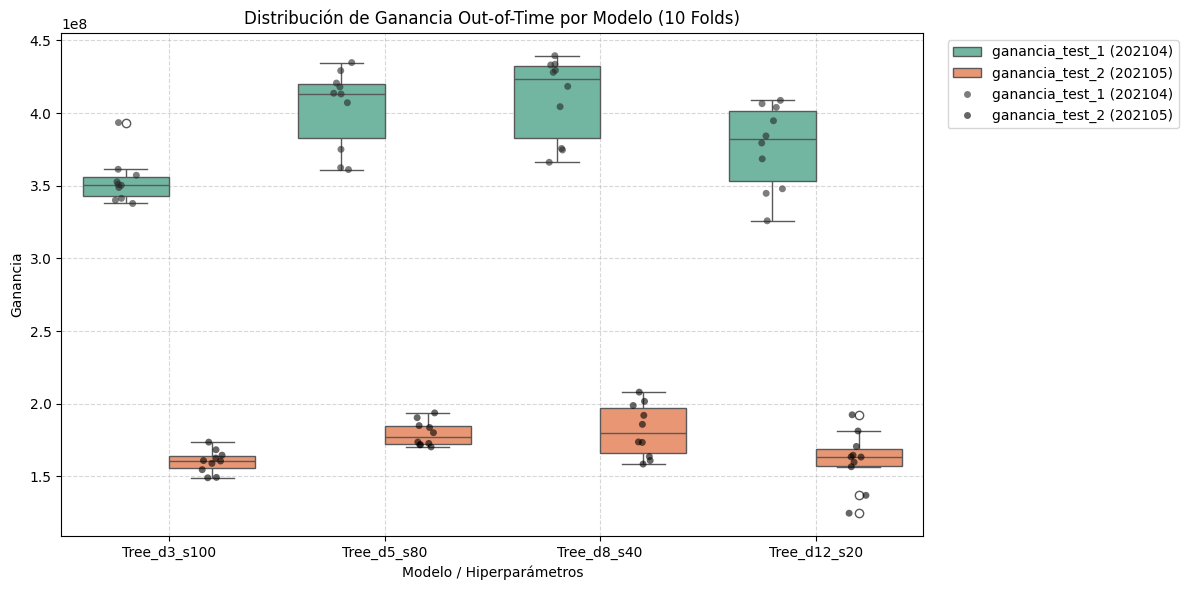

In [25]:
# Transformar a formato largo para graficar fácilmente con seaborn
df_plot = df_test.melt(
    id_vars=['modelo', 'fold'], 
    value_vars=['ganancia_test_1 (202104)', 'ganancia_test_2 (202105)'],
    var_name='periodo_test', 
    value_name='ganancia'
)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_plot, x='modelo', y='ganancia', hue='periodo_test', palette='Set2')
sns.stripplot(data=df_plot, x='modelo', y='ganancia', hue='periodo_test', dodge=True, color='black', alpha=0.6)
plt.title('Distribución de Ganancia Out-of-Time por Modelo (10 Folds)')
plt.xlabel('Modelo / Hiperparámetros')
plt.ylabel('Ganancia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Pendientes ver linea a linea (particion a particion) si se comportan parecido entre modelos 

Aleatoriedad futuro publi-priv

Como optimizar hiperparametros?

Optimizacion bayesiana

Exploracion versus explotacion

veo a ver que hay, donde encuentro, exploto

Problema de las reinas --> *LATIN HIPERCUBE SAMPLES* para tratar de cubrir el espacio de opciones de la manera mas optima posible
pa cada variable multiplicarla por 4 son 8 muestras --> inicializacion del conjunto de datos --> toma ganancia de cada una de estas cosas --> trata de predecir como es la funcion de ganancia -> cada x representa una combinacion de hiperparametros especifica , un punto dentro de 

(ojo con: algunos algoritmos minimizan en lugar de maximizar, ajustar/invertir)

estima la curva de ganancia de a intervalos dentro de ella misma

hoy usamos / recomiendan: TPE 
en los que se especifican tanto donde buscar como donde no buscar 

OPTUNA libreria o MLR para R
optuna.org 

tiene posibilidad de guardar las cosas en una base de datos --> sql light almacenar corridas y results.

la topografia no tiene un unico optimo !!!! es una serie de cadenas montañosas , pero hay optimos locales 
pq no conocemos la funcion subyacente -> de ahi el switch entre explotacion y exploracion

OMG a la vez necesito parametros para optimizar la busqueda pero no tenemos tiempo ni ganas aunque SAD las optimizaciones tb pueden overfittear

optimizar --> de los mejores--> explorar sus distribuciones en profundidad


In [9]:
import optuna
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.tree import DecisionTreeClassifier

# Desactivar logs detallados si quieres una salida más limpia
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Definir la función objetivo
def objective(trial):
    # Espacio de búsqueda de hiperparámetros
    params = {
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']), # categoricos pasa como lista
        'max_depth': trial.suggest_int('max_depth', 3, 25), # lim minimos y maximos para valores enteros 
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 500),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5, 200),
        'max_features': trial.suggest_float('max_features', 0.2, 1.0),
        'random_state': 42
    }
    
    # Validador sobre el mes de entrenamiento
    sss = StratifiedShuffleSplit(n_splits=5, test_size=0.3, random_state=42)
    ganancias_folds = []
    
    for train_index, test_index in sss.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[train_index], y_train.iloc[train_index]
        X_va, y_va = X_train.iloc[test_index], y_train.iloc[test_index]
        
        model = DecisionTreeClassifier(**params)
        model.fit(X_tr, y_tr)
        
        # Evaluar ganancia en el fold de validación
        gan = ganancia(model, X_va, y_va, prop=0.3)
        ganancias_folds.append(gan)
        
    # Optuna optimiza el promedio de ganancia obtenido en los folds
    return np.mean(ganancias_folds)

# 2. Crear y ejecutar el estudio
study = optuna.create_study(direction='maximize') # 'maximize' porque buscamos máxima ganancia
study.optimize(objective, n_trials=20, show_progress_bar=True) # llamamos a la funcion de arriba, con num de pruebas 

# 3. Mejores resultados
print("--- MEJOR EXPERIMENTO ---")
print(f"Mejor Ganancia Promedio: {study.best_value:,.2f}")
print("Mejores Hiperparámetros:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

c:\Users\carof\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Best trial: 5. Best value: 2.88677e+08: 100%|██████████| 20/20 [07:33<00:00, 22.66s/it]

--- MEJOR EXPERIMENTO ---
Mejor Ganancia Promedio: 288,676,666.67
Mejores Hiperparámetros:
  criterion: gini
  max_depth: 6
  min_samples_split: 399
  min_samples_leaf: 189
  max_features: 0.8079775320052178


C:\Users\carof\AppData\Local\Temp\ipykernel_29996\2523019916.py:4: ExperimentalWarning: optuna.visualization.matplotlib._contour.plot_contour is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_contour(study, params=['max_depth', 'min_samples_split'])


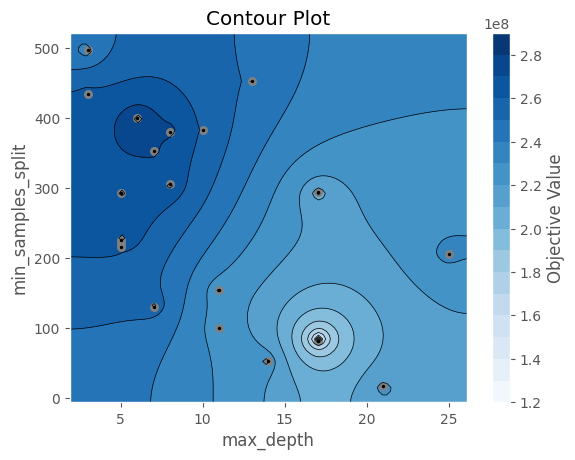

: 

In [ ]:
import matplotlib.pyplot as plt
import optuna.visualization.matplotlib as vis_plt

vis_plt.plot_contour(study, params=['max_depth', 'min_samples_split'])
plt.show()